In [51]:
import pandas as pd
import requests
from PIL import Image
import io
from IPython.display import display,clear_output
import ipywidgets as widgets

In [52]:
pokemon_df = pd.read_csv('data/pokemon_data.csv')
p_images_df = pd.read_csv('data/pokemon_801.csv')

In [53]:
merged_df = pd.merge(pokemon_df,p_images_df,on='name')

In [54]:
print(merged_df.iloc[0]["name"])
print(merged_df.iloc[0].image_url)

Bulbasaur
https://raw.githubusercontent.com/PokeAPI/sprites/master/sprites/pokemon/other/official-artwork/1.png


In [55]:
m_url = merged_df.loc[merged_df.name =="Meowth","image_url"].item()
m_url

'https://raw.githubusercontent.com/PokeAPI/sprites/master/sprites/pokemon/other/official-artwork/52.png'

I choose you...Vulpix,hp:38


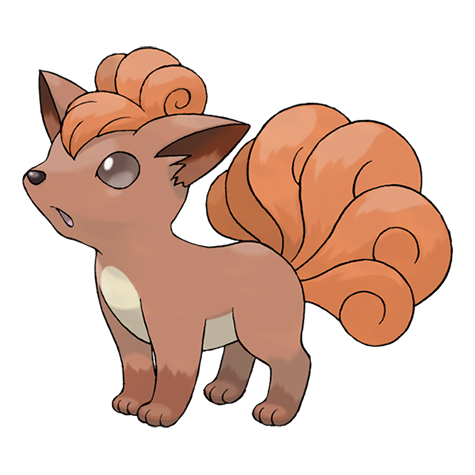

It is...Octillery,hp:75


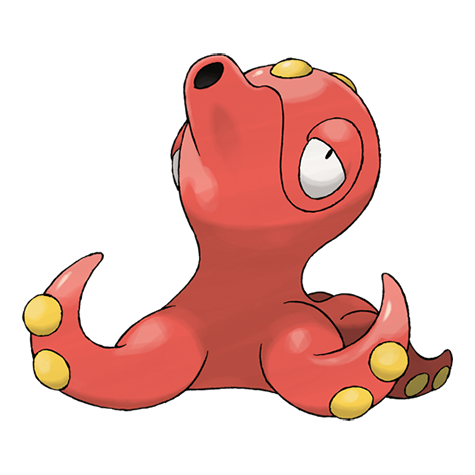

Octillery won!


In [56]:
my_pokemon = merged_df.sample().iloc[0] #iloc[0] to use sample fuction so it don't return all the dataframe
opp_pokemon = merged_df.sample().iloc[0]

#showcaseing pokemon image
#sending request to internet
pokemon_url = my_pokemon.image_url
response = requests.get(pokemon_url)
pokemon_img = Image.open(io.BytesIO(response.content)) #doing what web browser giving image from url

#save names
my_name = my_pokemon['name']
opp_name =opp_pokemon['name']

#show my pokemon
print(f"I choose you...{my_name},hp:{my_pokemon.hp}")
display(pokemon_img)

#showing opp pokemon img
print(f"It is...{opp_name},hp:{opp_pokemon.hp}")
opp_url = opp_pokemon.image_url
opp_response = requests.get(opp_url)
opp_img = Image.open(io.BytesIO(opp_response.content)) #doing what web browser giving image from url
display(opp_img)

if my_pokemon.hp>opp_pokemon.hp:
    print(f'{my_name} won!')
else:
    print(f'{opp_name} won!')


In [57]:
#making getting image code into a fuction
def get_image_from_url(url): #def is to define a fuction
    response = requests.get(url)
    img = Image.open(io.BytesIO(response.content))
    display(img)

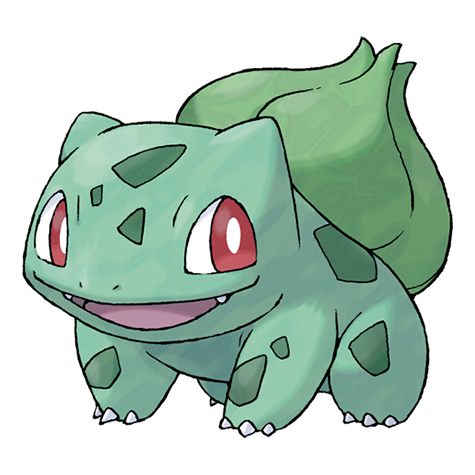

In [58]:
get_image_from_url("https://raw.githubusercontent.com/PokeAPI/sprites/master/sprites/pokemon/other/official-artwork/1.png")

I choose you...Mienfoo,hp:45


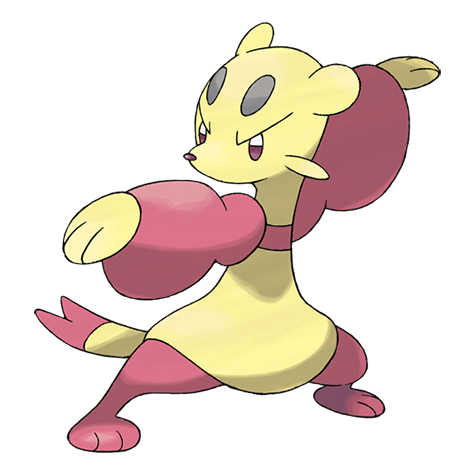

It is...Gothorita,hp:60


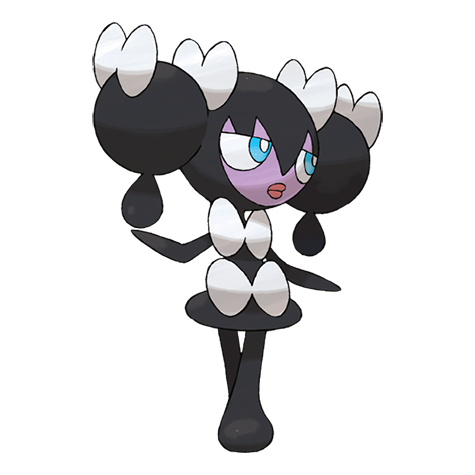

Gothorita won!


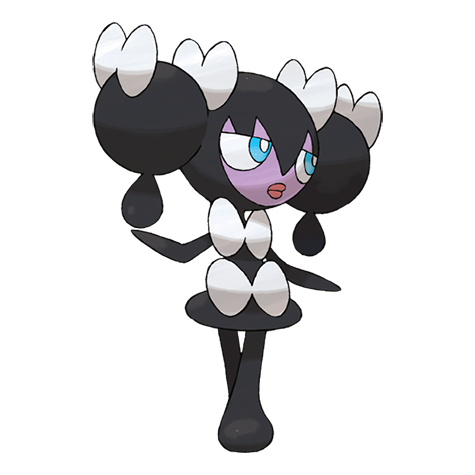

In [59]:
#simplify version
my_pokemon = merged_df.sample().iloc[0] #iloc[0] to use sample fuction so it don't return all the dataframe
opp_pokemon = merged_df.sample().iloc[0]

#showcaseing pokemon image
#sending request to internet
pokemon_url = my_pokemon.image_url
response = requests.get(pokemon_url)
pokemon_img = Image.open(io.BytesIO(response.content)) #doing what web browser giving image from url

#save names
my_name = my_pokemon['name']
opp_name =opp_pokemon['name']

#show my pokemon
print(f"I choose you...{my_name},hp:{my_pokemon.hp}")
display(pokemon_img)

#showing opp pokemon img
print(f"It is...{opp_name},hp:{opp_pokemon.hp}")
opp_url = opp_pokemon.image_url
opp_response = requests.get(opp_url)
opp_img = Image.open(io.BytesIO(opp_response.content)) #doing what web browser giving image from url
display(opp_img)

if my_pokemon.hp>opp_pokemon.hp:
    print(f'{my_name} won!')
    get_image_from_url(my_pokemon.image_url)

else:
    print(f'{opp_name} won!')
    get_image_from_url(opp_pokemon.image_url)


In [95]:

def battle():
    text_input = widgets.Text(
        placeholder='Who do you choose?',
        description='Choose your Pokemon:',
        style={'description_width': '150px'},
        layout=widgets.Layout(width='450px')
    )

    button = widgets.Button(
        description='Ready for battle!',
        button_style='danger'
    )

    output = widgets.Output()

    def on_battle_click(b):
        with output:
            clear_output()

            user_name = text_input.value.strip()

            # Find the Pokemon the user chose
            match = merged_df[
                merged_df['name'].str.lower() == user_name.lower()
            ]

            if match.empty:
                print('That is not a real Pokemon. Try again!')
                return

            # Use the Pokemon selected by the user
            my_pokemon = match.iloc[0]

            # Choose a random opponent
            opp_pokemon = merged_df.sample().iloc[0]

            # Show your Pokemon
            pokemon_url = my_pokemon.image_url
            response = requests.get(pokemon_url)
            pokemon_img = Image.open(io.BytesIO(response.content))

            my_name = my_pokemon['name']
            opp_name = opp_pokemon['name']

            print(f"I choose you... {my_name}, HP: {my_pokemon.hp}")
            display(pokemon_img)

            # Show opponent Pokemon
            print(f"It is... {opp_name}, HP: {opp_pokemon.hp}")

            opp_url = opp_pokemon.image_url
            opp_response = requests.get(opp_url)
            opp_img = Image.open(io.BytesIO(opp_response.content))
            display(opp_img)

            # Determine the winner
            if my_pokemon.hp > opp_pokemon.hp:
                print(f'{my_name} won!')
                get_image_from_url(my_pokemon.image_url)

            elif my_pokemon.hp < opp_pokemon.hp:
                print(f'{opp_name} won!')
                get_image_from_url(opp_pokemon.image_url)

            else:
                print("It's a tie!")

    # IMPORTANT: Keep these lines outside on_battle_click()
    button.on_click(on_battle_click)
    display(widgets.VBox([text_input, button, output]))



In [96]:
battle()